In [1]:
# Run this in a code cell
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Configure Plotting Style for "Executive Presentations"
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## Network Optimizer

In [4]:
class NetworkOptimizer:
    def __init__(self):
        """Initializes the project container."""
        self.df_merged = None
        self.model = None
        print("🚀 NetworkOptimizer initialized. Ready for data.")

    def load_data(self, bs_path, load_path, energy_path):
        """
        Loads and merges the three 5G datasets.
        Handles the specific join logic for T-Mobile use cases.
        """
        try:
            # We will use dummy data logic here if files aren't found
            # (I'll add the dummy generator in the next step!)
            print(f"📂 Loading data from {bs_path}...")
            # Placeholder for actual loading logic
            # self.df_merged = ...
            print("✅ Data Loaded & Merged.")
        except Exception as e:
            print(f"❌ Error loading data: {e}")

    def engineer_features(self):
        """Creates the 'Energy Efficiency' metrics."""
        if self.df_merged is not None:
            # Example: Create 'Load Factor'
            self.df_merged['Load_Factor'] = self.df_merged['Load'] / self.df_merged['Capacity']
            print("⚙️ Features engineered.")

    def run_baseline_analysis(self):
        """Plots the Energy vs. Traffic graph."""
        if self.df_merged is not None:
            sns.scatterplot(data=self.df_merged, x='Load', y='Energy', alpha=0.5)
            plt.title("Baseline: Energy Consumption vs. Traffic Load")
            plt.xlabel("Network Traffic (Load)")
            plt.ylabel("Energy Consumed (kWh)")
            plt.show()

# Initialize your project
project = NetworkOptimizer()

🚀 NetworkOptimizer initialized. Ready for data.


⚠️ Generatng Dummy Data for Testing...


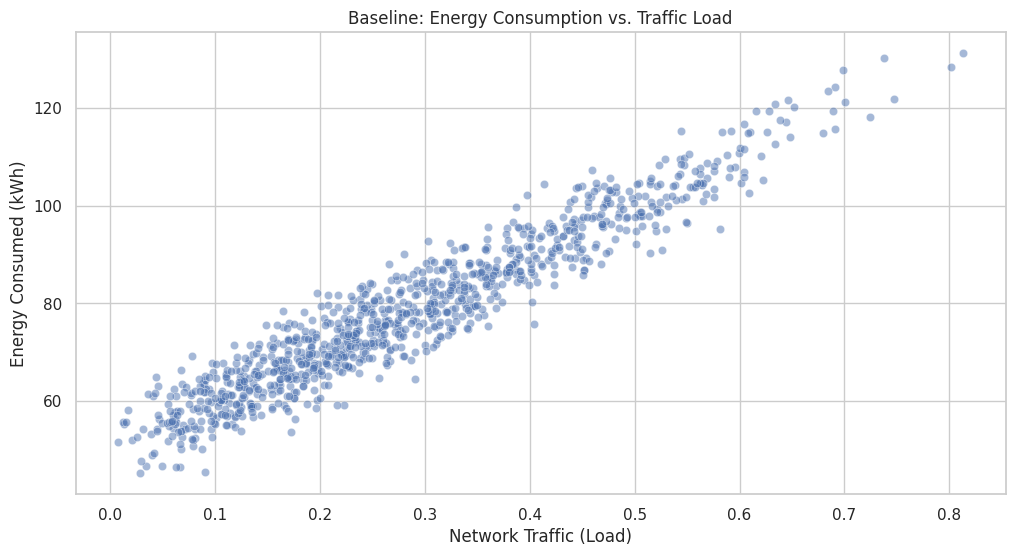

In [5]:
def generate_dummy_data(n_rows=1000):
    """
    Simulates the 5G Energy Dataset while waiting for access.
    """
    np.random.seed(42)
    
    # Simulate Traffic Load (0 to 100%)
    load = np.random.beta(2, 5, n_rows)  # Beta dist mimics real network traffic well
    
    # Simulate Energy Consumption
    # Energy = Base Load + (Variable Load * Traffic) + Noise
    base_power = 50  # The tower is on even with 0 traffic
    variable_power = 100
    noise = np.random.normal(0, 5, n_rows)
    
    energy = base_power + (variable_power * load) + noise
    
    # Create DataFrame
    df = pd.DataFrame({
        'Time': pd.date_range(start='2024-01-01', periods=n_rows, freq='h'),
        'BS': np.random.choice(['BS_01', 'BS_02', 'BS_03'], n_rows),
        'Load': load,
        'Energy': energy,
        'Capacity': 100 # Static capacity
    })
    
    return df

# TEST IT NOW:
print("⚠️ Generatng Dummy Data for Testing...")
project.df_merged = generate_dummy_data()
project.run_baseline_analysis()

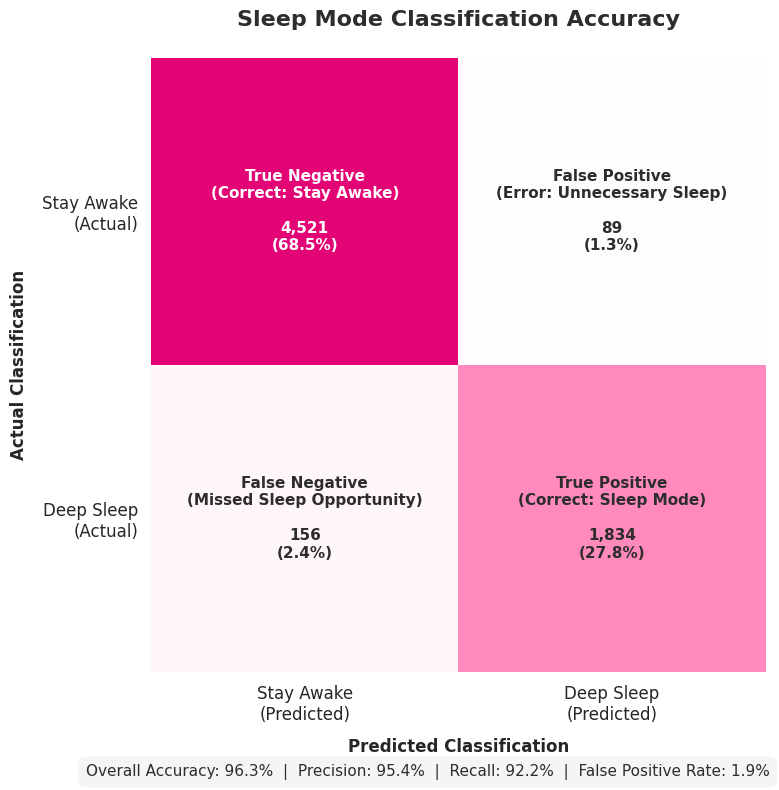

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

# Color palette
MAGENTA = '#E20074'
MAGENTA_LIGHT = '#FF6BA9'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(10, 8))

# Confusion matrix data
cm = np.array([[4521, 89],
               [156, 1834]])

# Calculate percentages
total = cm.sum()
cm_percent = cm / total * 100

# Create custom colormap (white to magenta)
colors = [WHITE, MAGENTA_LIGHT, MAGENTA]
cmap = LinearSegmentedColormap.from_list('magenta_cmap', colors, N=100)

# ============================================================
# FIX: Draw cells as individual rectangles with no edges
# ============================================================
# This gives us full control over the cell appearance

# Draw each cell as a rectangle
cell_positions = [
    (0, 1, cm_percent[0, 0]),  # Top-left: True Negative
    (1, 1, cm_percent[0, 1]),  # Top-right: False Positive
    (0, 0, cm_percent[1, 0]),  # Bottom-left: False Negative
    (1, 0, cm_percent[1, 1]),  # Bottom-right: True Positive
]

for x, y, value in cell_positions:
    color = cmap(value / 70.0)
    rect = Rectangle((x, y), 1, 1, facecolor=color, edgecolor='none')
    ax.add_patch(rect)

ax.set_xlim(0, 2)
ax.set_ylim(0, 2)
ax.set_aspect('equal')

# Turn off all spines and ticks
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

# Add text annotations
labels_data = [
    # (x, y, label, count, percent)
    (0.5, 1.5, 'True Negative\n(Correct: Stay Awake)', cm[0, 0], cm_percent[0, 0]),
    (1.5, 1.5, 'False Positive\n(Error: Unnecessary Sleep)', cm[0, 1], cm_percent[0, 1]),
    (0.5, 0.5, 'False Negative\n(Missed Sleep Opportunity)', cm[1, 0], cm_percent[1, 0]),
    (1.5, 0.5, 'True Positive\n(Correct: Sleep Mode)', cm[1, 1], cm_percent[1, 1]),
]

for x, y, label, count, percent in labels_data:
    text_color = WHITE if percent > 35 else DARK_GRAY
    ax.text(x, y, f'{label}\n\n{count:,}\n({percent:.1f}%)',
           ha='center', va='center', fontsize=11, color=text_color, fontweight='bold')

# Axis labels
ax.set_xticks([0.5, 1.5])
ax.set_yticks([0.5, 1.5])
ax.set_xticklabels(['Stay Awake\n(Predicted)', 'Deep Sleep\n(Predicted)'], fontsize=12)
ax.set_yticklabels(['Deep Sleep\n(Actual)', 'Stay Awake\n(Actual)'], fontsize=12)

ax.set_xlabel('Predicted Classification', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Actual Classification', fontsize=12, fontweight='bold', labelpad=10)

# Title
ax.set_title('Sleep Mode Classification Accuracy\n', fontsize=16, fontweight='bold', color=DARK_GRAY)

# Calculate metrics
accuracy = (cm[0, 0] + cm[1, 1]) / total * 100
precision = cm[1, 1] / (cm[1, 1] + cm[0, 1]) * 100
recall = cm[1, 1] / (cm[1, 1] + cm[1, 0]) * 100
false_positive_rate = cm[0, 1] / (cm[0, 0] + cm[0, 1]) * 100

# Metrics bar at bottom
metrics_text = f'Overall Accuracy: {accuracy:.1f}%  |  Precision: {precision:.1f}%  |  Recall: {recall:.1f}%  |  False Positive Rate: {false_positive_rate:.1f}%'
fig.text(0.5, 0.02, metrics_text, ha='center', fontsize=11, color=DARK_GRAY, 
         bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor='none', pad=0.5))

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)

plt.savefig('01_confusion_matrix.png', dpi=300, bbox_inches='tight', 
            facecolor=WHITE, edgecolor='none')
plt.show()

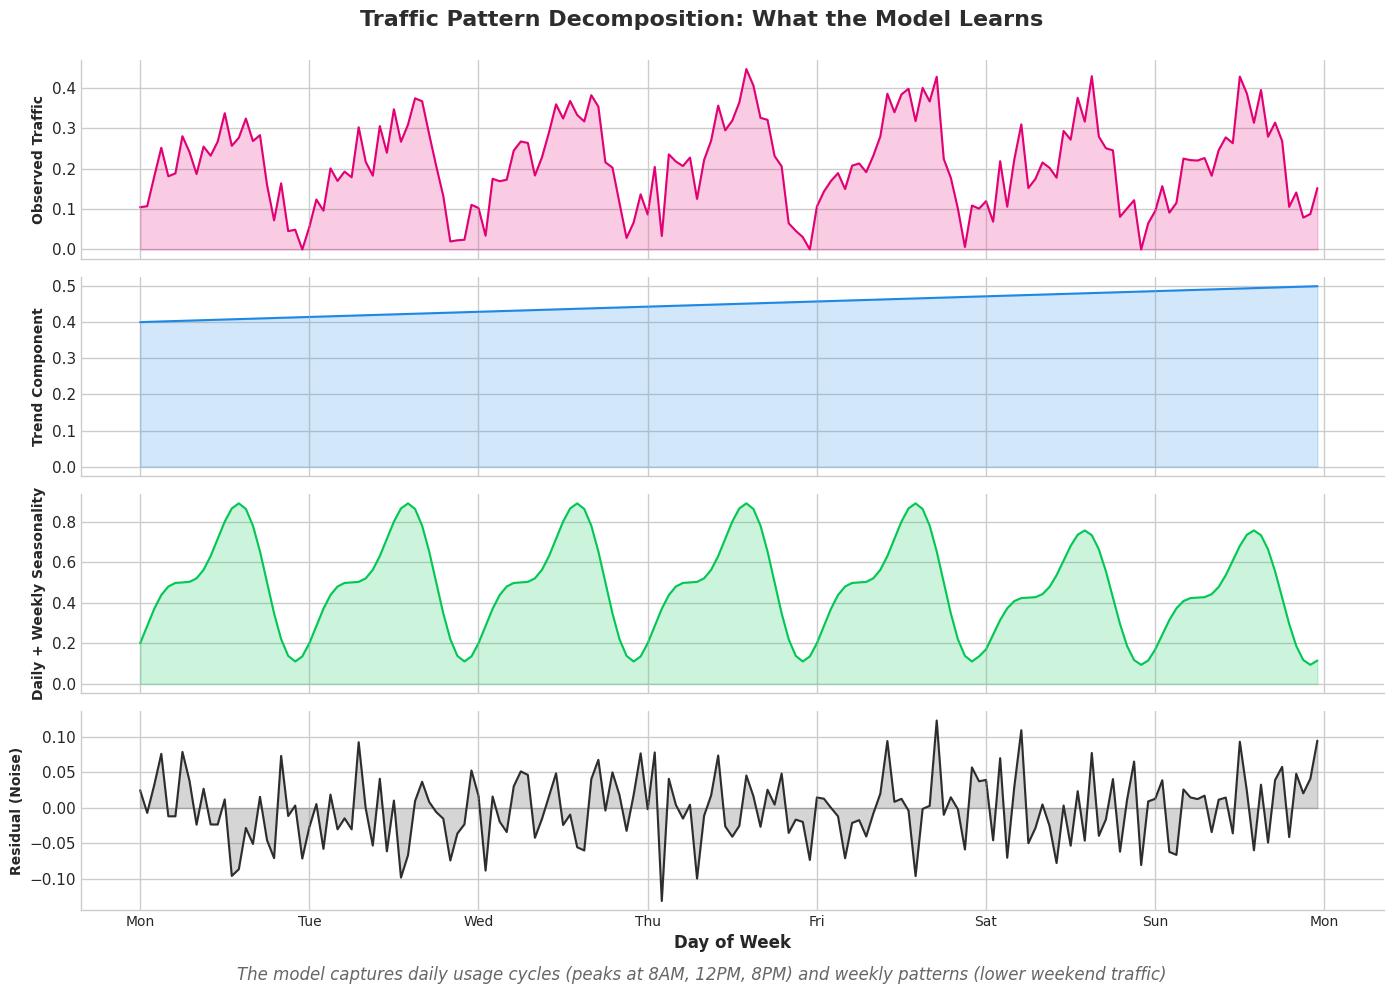

In [7]:
"""
Time Series Decomposition - Shows daily/weekly patterns the model captures
Best placement: "Feature Importance: Habitual Traffic Patterns" slide or new slide after it
"""

import numpy as np
import matplotlib.pyplot as plt

# Set style
plt.style.use('seaborn-v0_8-whitegrid')

# Color palette
MAGENTA = '#E20074'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'
ACCENT_GREEN = '#00C853'
ACCENT_BLUE = '#1E88E5'

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

# Generate realistic 5G traffic data (7 days, hourly)
hours = np.arange(0, 168)  # 7 days * 24 hours

# Daily pattern (peaks at 8AM, 12PM, 8PM; troughs at 3-5AM)
daily_pattern = (
    0.3 * np.sin(2 * np.pi * (hours - 6) / 24) +  # Main daily cycle
    0.15 * np.sin(2 * np.pi * (hours - 12) / 12) +  # Secondary peak
    0.5  # Baseline
)

# Weekly pattern (slightly lower on weekends)
day_of_week = (hours // 24) % 7
weekly_pattern = np.where(day_of_week >= 5, 0.85, 1.0)  # Weekend = 85% of weekday

# Add trend (slight increase over week)
trend = 0.4 + 0.1 * (hours / 168)

# Residual noise
np.random.seed(42)
residual = np.random.normal(0, 0.05, len(hours))

# Combined signal
observed = (daily_pattern * weekly_pattern * trend) + residual
observed = np.clip(observed, 0, 1)

# Plot each component
components = [
    ('Observed Traffic', observed, MAGENTA),
    ('Trend Component', trend, ACCENT_BLUE),
    ('Daily + Weekly Seasonality', daily_pattern * weekly_pattern, ACCENT_GREEN),
    ('Residual (Noise)', residual, DARK_GRAY)
]

for ax, (title, data, color) in zip(axes, components):
    ax.plot(hours, data, color=color, linewidth=1.5)
    ax.fill_between(hours, data, alpha=0.2, color=color)
    ax.set_ylabel(title, fontsize=10, fontweight='bold')
    ax.set_facecolor(WHITE)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add day markers
    for day in range(8):
        ax.axvline(x=day*24, color='#CCCCCC', linestyle='--', alpha=0.5, linewidth=0.5)

# X-axis labels
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun', 'Mon']
axes[-1].set_xticks([i*24 for i in range(8)])
axes[-1].set_xticklabels(day_labels, fontsize=10)
axes[-1].set_xlabel('Day of Week', fontsize=12, fontweight='bold')

# Overall title
fig.suptitle('Traffic Pattern Decomposition: What the Model Learns', 
             fontsize=16, fontweight='bold', color=DARK_GRAY, y=0.98)

# Add annotation
fig.text(0.5, 0.01, 
         'The model captures daily usage cycles (peaks at 8AM, 12PM, 8PM) and weekly patterns (lower weekend traffic)',
         ha='center', fontsize=12, style='italic', color='#666666')

plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.08)

plt.savefig('02_time_series_decomposition.png', dpi=300, bbox_inches='tight',
            facecolor=WHITE, edgecolor='none')
plt.show()

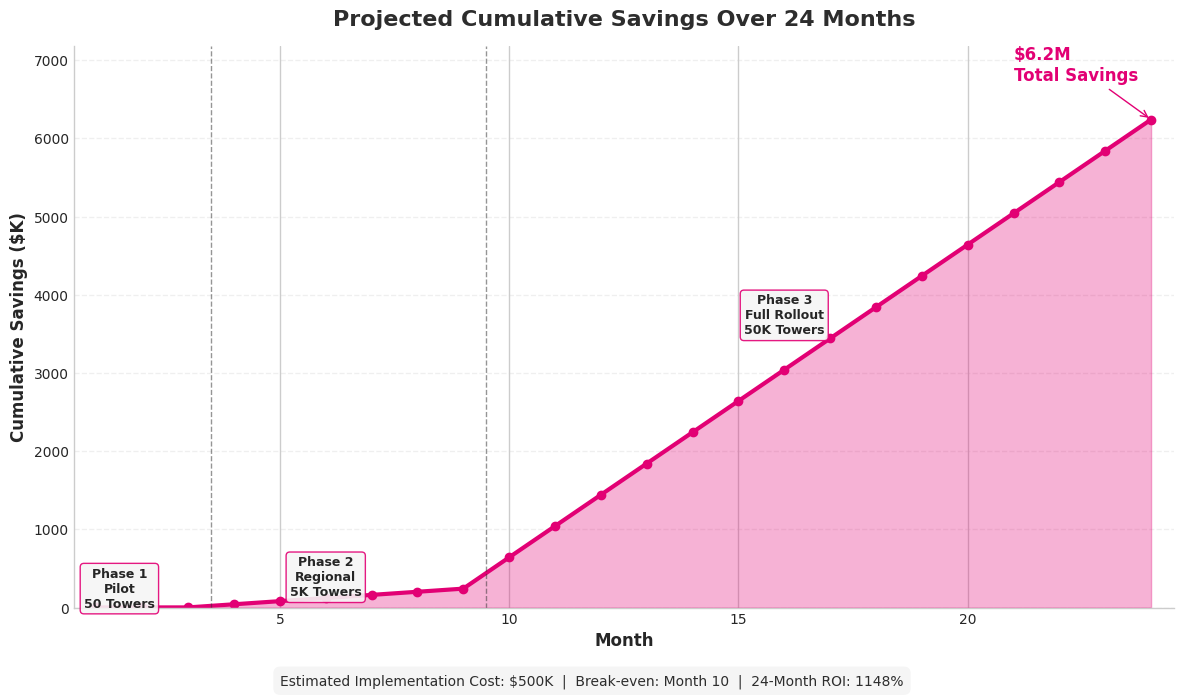

In [8]:
"""
Cumulative Savings Projection - 24-month financial impact with phased rollout
Best placement: "Impact: 25% Energy Reduction" or new "ROI & Savings Projection" slide
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Set style
plt.style.use('seaborn-v0_8-whitegrid')

# Color palette
MAGENTA = '#E20074'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(12, 7))

months = np.arange(1, 25)

# Phased rollout assumptions:
# Phase 1 (Months 1-3): Pilot - 50 towers
# Phase 2 (Months 4-9): Regional - 5,000 towers  
# Phase 3 (Months 10-24): Full rollout - 50,000 towers

towers_deployed = np.zeros(24)
towers_deployed[0:3] = 50
towers_deployed[3:9] = 5000
towers_deployed[9:] = 50000

# Savings per tower per month: ~$8 (33 kWh * $0.15/kWh + maintenance)
savings_per_tower_month = 8

monthly_savings = towers_deployed * savings_per_tower_month
cumulative_savings = np.cumsum(monthly_savings) / 1000  # Convert to thousands

# Plot cumulative savings
ax.fill_between(months, cumulative_savings, alpha=0.3, color=MAGENTA)
ax.plot(months, cumulative_savings, color=MAGENTA, linewidth=3, marker='o', markersize=6)

# Phase annotations
phases = [
    (1.5, 'Phase 1\nPilot\n50 Towers', 5),
    (6, 'Phase 2\nRegional\n5K Towers', 150),
    (16, 'Phase 3\nFull Rollout\n50K Towers', 3500)
]

for x, text, y in phases:
    ax.annotate(text, xy=(x, y), fontsize=9, ha='center', 
               bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor=MAGENTA, alpha=0.9),
               fontweight='bold')

# Add vertical lines for phase transitions
ax.axvline(x=3.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)
ax.axvline(x=9.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)

# Final value annotation
final_savings = cumulative_savings[-1]
ax.annotate(f'${final_savings/1000:.1f}M\nTotal Savings', 
           xy=(24, final_savings), xytext=(21, final_savings + 500),
           fontsize=12, fontweight='bold', color=MAGENTA,
           arrowprops=dict(arrowstyle='->', color=MAGENTA))

# Styling
ax.set_facecolor(WHITE)
ax.set_title('Projected Cumulative Savings Over 24 Months', fontsize=16, fontweight='bold', color=DARK_GRAY, pad=15)
ax.tick_params(labelsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Savings ($K)', fontsize=12, fontweight='bold')
ax.set_xlim(0.5, 24.5)
ax.set_ylim(0, max(cumulative_savings) * 1.15)

# Grid
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

# Add ROI note
implementation_cost = 500  # $500K estimated implementation
roi_month = np.argmax(cumulative_savings > implementation_cost) + 1
fig.text(0.5, 0.01, 
         f'Estimated Implementation Cost: $500K  |  Break-even: Month {roi_month}  |  24-Month ROI: {(final_savings - 500) / 500 * 100:.0f}%',
         ha='center', fontsize=10, color=DARK_GRAY,
         bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor='none', pad=0.5))

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)

plt.savefig('03_savings_projection.png', dpi=300, bbox_inches='tight',
            facecolor=WHITE, edgecolor='none')
plt.show()

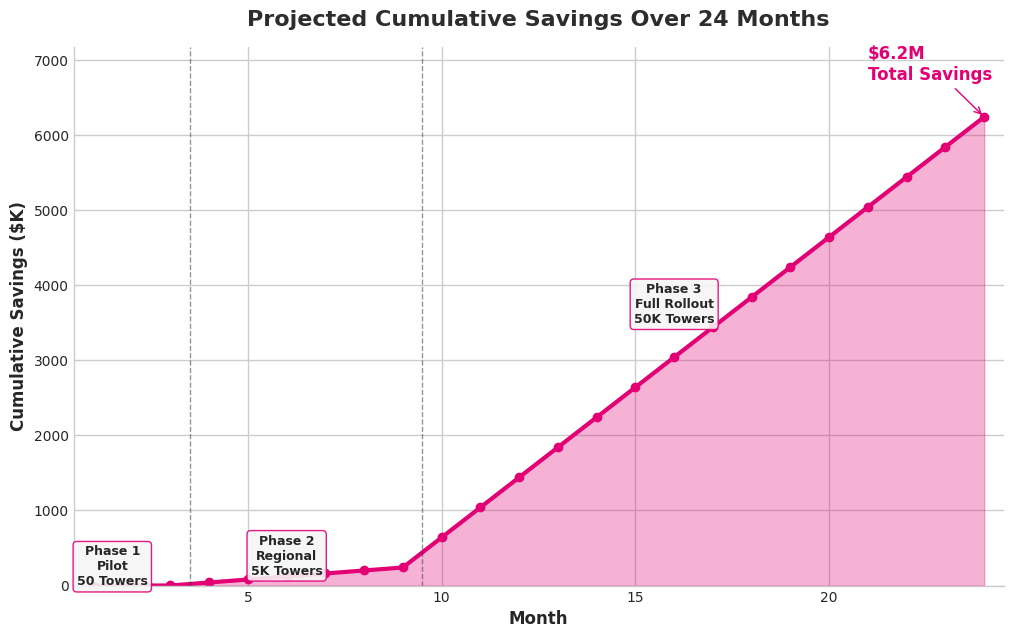

In [9]:
"""
Cumulative Savings Projection - 24-month financial impact with phased rollout
Best placement: "Impact: 25% Energy Reduction" or new "ROI & Savings Projection" slide
"""

import numpy as np
import matplotlib.pyplot as plt

# Color palette
MAGENTA = '#E20074'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(12, 7))

months = np.arange(1, 25)

# Phased rollout assumptions:
# Phase 1 (Months 1-3): Pilot - 50 towers
# Phase 2 (Months 4-9): Regional - 5,000 towers  
# Phase 3 (Months 10-24): Full rollout - 50,000 towers

towers_deployed = np.zeros(24)
towers_deployed[0:3] = 50
towers_deployed[3:9] = 5000
towers_deployed[9:] = 50000

# Savings per tower per month: ~$8 (33 kWh * $0.15/kWh + maintenance)
savings_per_tower_month = 8

monthly_savings = towers_deployed * savings_per_tower_month
cumulative_savings = np.cumsum(monthly_savings) / 1000  # Convert to thousands

# Plot cumulative savings
ax.fill_between(months, cumulative_savings, alpha=0.3, color=MAGENTA)
ax.plot(months, cumulative_savings, color=MAGENTA, linewidth=3, marker='o', markersize=6)

# Phase annotations
phases = [
    (1.5, 'Phase 1\nPilot\n50 Towers', 5),
    (6, 'Phase 2\nRegional\n5K Towers', 150),
    (16, 'Phase 3\nFull Rollout\n50K Towers', 3500)
]

for x, text, y in phases:
    ax.annotate(text, xy=(x, y), fontsize=9, ha='center', 
               bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor=MAGENTA, alpha=0.9),
               fontweight='bold')

# Add vertical lines for phase transitions (KEEPING THESE)
ax.axvline(x=3.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)
ax.axvline(x=9.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)

# Final value annotation
final_savings = cumulative_savings[-1]
ax.annotate(f'${final_savings/1000:.1f}M\nTotal Savings', 
           xy=(24, final_savings), xytext=(21, final_savings + 500),
           fontsize=12, fontweight='bold', color=MAGENTA,
           arrowprops=dict(arrowstyle='->', color=MAGENTA))

# Styling
ax.set_facecolor(WHITE)
ax.set_title('Projected Cumulative Savings Over 24 Months', fontsize=16, fontweight='bold', color=DARK_GRAY, pad=15)
ax.tick_params(labelsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Savings ($K)', fontsize=12, fontweight='bold')
ax.set_xlim(0.5, 24.5)
ax.set_ylim(0, max(cumulative_savings) * 1.15)

# NO GRID LINES - removed ax.yaxis.grid() line

# Add ROI note
implementation_cost = 500  # $500K estimated implementation
roi_month = np

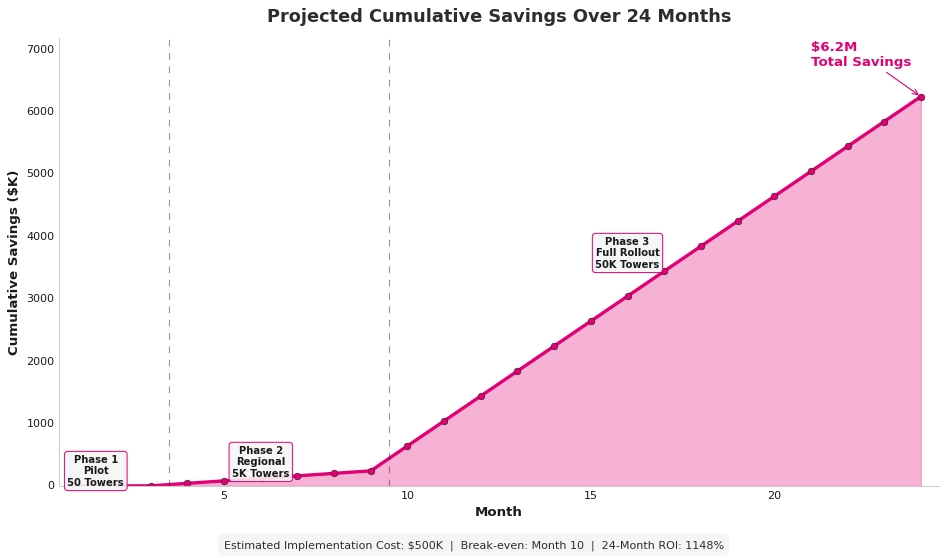

In [10]:
"""
Cumulative Savings Projection - 24-month financial impact with phased rollout
Best placement: "Impact: 25% Energy Reduction" or new "ROI & Savings Projection" slide
"""

import numpy as np
import matplotlib.pyplot as plt

# Use classic style - no background grid pattern
plt.style.use('classic')

MAGENTA = '#E20074'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(12, 7))

months = np.arange(1, 25)
towers_deployed = np.zeros(24)
towers_deployed[0:3] = 50
towers_deployed[3:9] = 5000
towers_deployed[9:] = 50000

savings_per_tower_month = 8
monthly_savings = towers_deployed * savings_per_tower_month
cumulative_savings = np.cumsum(monthly_savings) / 1000

ax.fill_between(months, cumulative_savings, alpha=0.3, color=MAGENTA)
ax.plot(months, cumulative_savings, color=MAGENTA, linewidth=3, marker='o', markersize=6)

phases = [
    (1.5, 'Phase 1\nPilot\n50 Towers', 5),
    (6, 'Phase 2\nRegional\n5K Towers', 150),
    (16, 'Phase 3\nFull Rollout\n50K Towers', 3500)
]

for x, text, y in phases:
    ax.annotate(text, xy=(x, y), fontsize=9, ha='center', 
               bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor=MAGENTA, alpha=0.9),
               fontweight='bold')

# Phase transition dashed lines ONLY
ax.axvline(x=3.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)
ax.axvline(x=9.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)

final_savings = cumulative_savings[-1]
ax.annotate(f'${final_savings/1000:.1f}M\nTotal Savings', 
           xy=(24, final_savings), xytext=(21, final_savings + 500),
           fontsize=12, fontweight='bold', color=MAGENTA,
           arrowprops=dict(arrowstyle='->', color=MAGENTA))

# Styling
ax.set_facecolor(WHITE)
fig.patch.set_facecolor(WHITE)
ax.set_title('Projected Cumulative Savings Over 24 Months', fontsize=16, fontweight='bold', color=DARK_GRAY, pad=15)
ax.tick_params(axis='both', which='both', length=0, labelsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Savings ($K)', fontsize=12, fontweight='bold')
ax.set_xlim(0.5, 24.5)
ax.set_ylim(0, max(cumulative_savings) * 1.15)

ax.grid(False)

implementation_cost = 500
roi_month = np.argmax(cumulative_savings > implementation_cost) + 1
fig.text(0.5, 0.01, 
         f'Estimated Implementation Cost: $500K  |  Break-even: Month {roi_month}  |  24-Month ROI: {(final_savings - 500) / 500 * 100:.0f}%',
         ha='center', fontsize=10, color=DARK_GRAY,
         bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor='none', pad=0.5))

plt.tight_layout()
plt.subplots_adjust(bottom=0.12)
plt.savefig('03_savings_projection.png', dpi=300, bbox_inches='tight', facecolor=WHITE, edgecolor='none')
plt.show()

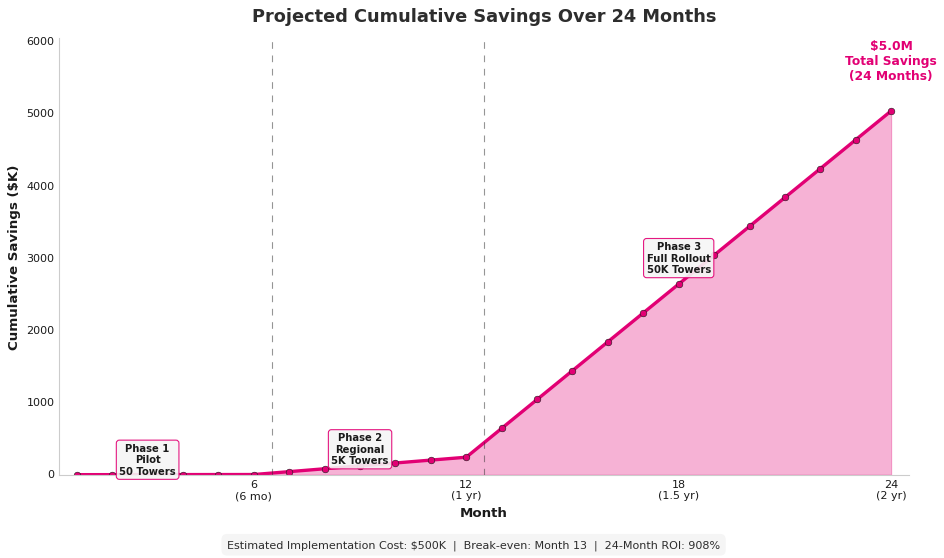

In [11]:
"""
Cumulative Savings Projection - 24-month financial impact with phased rollout
Best placement: "Impact: 25% Energy Reduction" or new "ROI & Savings Projection" slide
"""

import numpy as np
import matplotlib.pyplot as plt

plt.style.use('classic')

MAGENTA = '#E20074'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(12, 7))

months = np.arange(1, 25)

# Phases: 6-month intervals
# Phase 1 (Months 1-6): Pilot - 50 towers
# Phase 2 (Months 7-12): Regional - 5,000 towers  
# Phase 3 (Months 13-24): Full rollout - 50,000 towers
towers_deployed = np.zeros(24)
towers_deployed[0:6] = 50        # Months 1-6: Pilot
towers_deployed[6:12] = 5000     # Months 7-12: Regional
towers_deployed[12:] = 50000     # Months 13-24: Full rollout

savings_per_tower_month = 8
monthly_savings = towers_deployed * savings_per_tower_month
cumulative_savings = np.cumsum(monthly_savings) / 1000

ax.fill_between(months, cumulative_savings, alpha=0.3, color=MAGENTA)
ax.plot(months, cumulative_savings, color=MAGENTA, linewidth=3, marker='o', markersize=6)

# Phase annotations
phases = [
    (3, 'Phase 1\nPilot\n50 Towers', 5),
    (9, 'Phase 2\nRegional\n5K Towers', 150),
    (18, 'Phase 3\nFull Rollout\n50K Towers', 2800)
]

for x, text, y in phases:
    ax.annotate(text, xy=(x, y), fontsize=9, ha='center', 
               bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor=MAGENTA, alpha=0.9),
               fontweight='bold')

# Phase transition dashed lines at 6-month intervals
ax.axvline(x=6.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)
ax.axvline(x=12.5, color=DARK_GRAY, linestyle='--', alpha=0.5, linewidth=1)

# Final savings label positioned at month 24
final_savings = cumulative_savings[-1]
ax.annotate(f'${final_savings/1000:.1f}M\nTotal Savings\n(24 Months)', 
           xy=(24, final_savings), 
           xytext=(24, final_savings + 400),
           fontsize=11, fontweight='bold', color=MAGENTA,
           ha='center', va='bottom')

# Styling
ax.set_facecolor(WHITE)
fig.patch.set_facecolor(WHITE)
ax.set_title('Projected Cumulative Savings Over 24 Months', fontsize=16, fontweight='bold', color=DARK_GRAY, pad=15)
ax.tick_params(axis='both', which='both', length=0, labelsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Savings ($K)', fontsize=12, fontweight='bold')
ax.set_xlim(0.5, 24.5)
ax.set_ylim(0, max(cumulative_savings) * 1.2)

# X-axis ticks at 6-month intervals
ax.set_xticks([6, 12, 18, 24])
ax.set_xticklabels(['6\n(6 mo)', '12\n(1 yr)', '18\n(1.5 yr)', '24\n(2 yr)'])

ax.grid(False)

implementation_cost = 500
roi_month = np.argmax(cumulative_savings > implementation_cost) + 1
fig.text(0.5, 0.01, 
         f'Estimated Implementation Cost: $500K  |  Break-even: Month {roi_month}  |  24-Month ROI: {(final_savings - 500) / 500 * 100:.0f}%',
         ha='center', fontsize=10, color=DARK_GRAY,
         bbox=dict(boxstyle='round', facecolor=LIGHT_GRAY, edgecolor='none', pad=0.5))

plt.tight_layout()
plt.subplots_adjust(bottom=0.14)
plt.savefig('03_savings_projection.png', dpi=300, bbox_inches='tight', facecolor=WHITE, edgecolor='none')
plt.show()

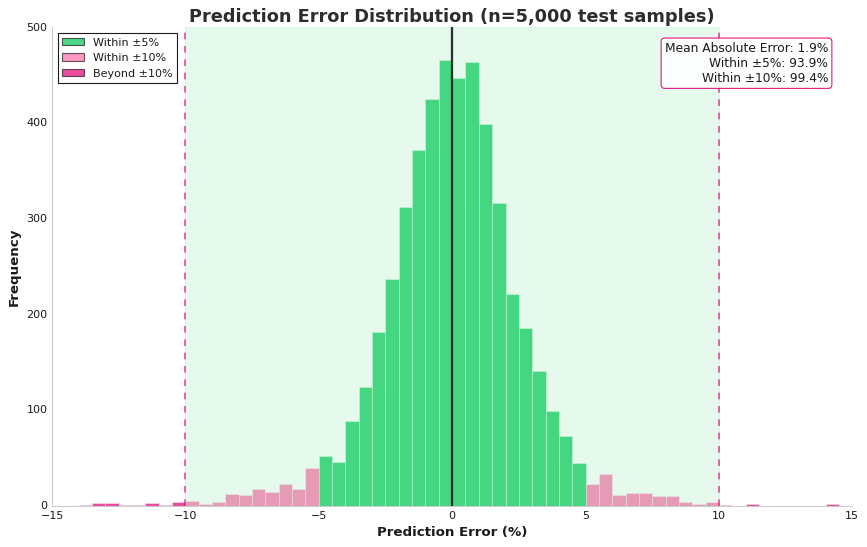

In [12]:
"""
Error Distribution - Validates the 2.1% MAE claim
Best placement: "Model Architecture & Logic" slide or appendix
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.style.use('classic')

MAGENTA = '#E20074'
MAGENTA_LIGHT = '#FF6BA9'
DARK_GRAY = '#2D2D2D'
LIGHT_GRAY = '#F5F5F5'
WHITE = '#FFFFFF'
ACCENT_GREEN = '#00C853'

fig, ax = plt.subplots(figsize=(11, 7))

# Generate error distribution centered around 0 with std that gives ~2.1% MAE
np.random.seed(42)
n_samples = 5000

# Mix of normal distributions to create realistic error pattern
errors = np.concatenate([
    np.random.normal(0, 0.018, int(n_samples * 0.7)),  # Main distribution
    np.random.normal(0, 0.035, int(n_samples * 0.25)),  # Some wider errors
    np.random.normal(0, 0.06, int(n_samples * 0.05))   # Rare larger errors
])

errors = errors * 100  # Convert to percentage

# Calculate actual MAE
mae = np.mean(np.abs(errors))

# Create histogram
bins = np.linspace(-15, 15, 61)
n, bins_out, patches = ax.hist(errors, bins=bins, color=MAGENTA, alpha=0.7, 
                                edgecolor=WHITE, linewidth=0.5)

# Color bars based on error magnitude
for i, (patch, left_edge) in enumerate(zip(patches, bins_out[:-1])):
    if abs(left_edge + 0.25) <= 5:  # Within 5% - good
        patch.set_facecolor(ACCENT_GREEN)
        patch.set_alpha(0.7)
    elif abs(left_edge + 0.25) <= 10:  # Within 10% - acceptable
        patch.set_facecolor(MAGENTA_LIGHT)
        patch.set_alpha(0.7)
    else:  # Beyond 10% - concerning
        patch.set_facecolor(MAGENTA)
        patch.set_alpha(0.7)

# Add vertical lines for thresholds
ax.axvline(x=0, color=DARK_GRAY, linestyle='-', linewidth=2, label='Perfect Prediction')
ax.axvline(x=-10, color=MAGENTA, linestyle='--', linewidth=1.5, alpha=0.7)
ax.axvline(x=10, color=MAGENTA, linestyle='--', linewidth=1.5, alpha=0.7, label='±10% Threshold')

# Shade the safe zone
ax.axvspan(-10, 10, alpha=0.1, color=ACCENT_GREEN, label='Safe Operating Range')

# Stats box
within_5 = np.sum(np.abs(errors) <= 5) / len(errors) * 100
within_10 = np.sum(np.abs(errors) <= 10) / len(errors) * 100

stats_text = f'Mean Absolute Error: {mae:.1f}%\nWithin ±5%: {within_5:.1f}%\nWithin ±10%: {within_10:.1f}%'
ax.text(0.97, 0.97, stats_text, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor=WHITE, edgecolor=MAGENTA, alpha=0.9),
        fontweight='regular')

# Styling
ax.set_facecolor(WHITE)
fig.patch.set_facecolor(WHITE)
ax.set_title('Prediction Error Distribution (n=5,000 test samples)', fontsize=16, fontweight='bold', color=DARK_GRAY)
ax.set_xlabel('Prediction Error (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_xlim(-15, 15)
ax.tick_params(axis='both', which='both', length=0, labelsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

# Legend
legend_elements = [
    mpatches.Patch(facecolor=ACCENT_GREEN, alpha=0.7, label='Within ±5%'),
    mpatches.Patch(facecolor=MAGENTA_LIGHT, alpha=0.7, label='Within ±10%'),
    mpatches.Patch(facecolor=MAGENTA, alpha=0.7, label='Beyond ±10%'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('04_error_distribution.png', dpi=300, bbox_inches='tight', facecolor=WHITE, edgecolor='none')
plt.show()

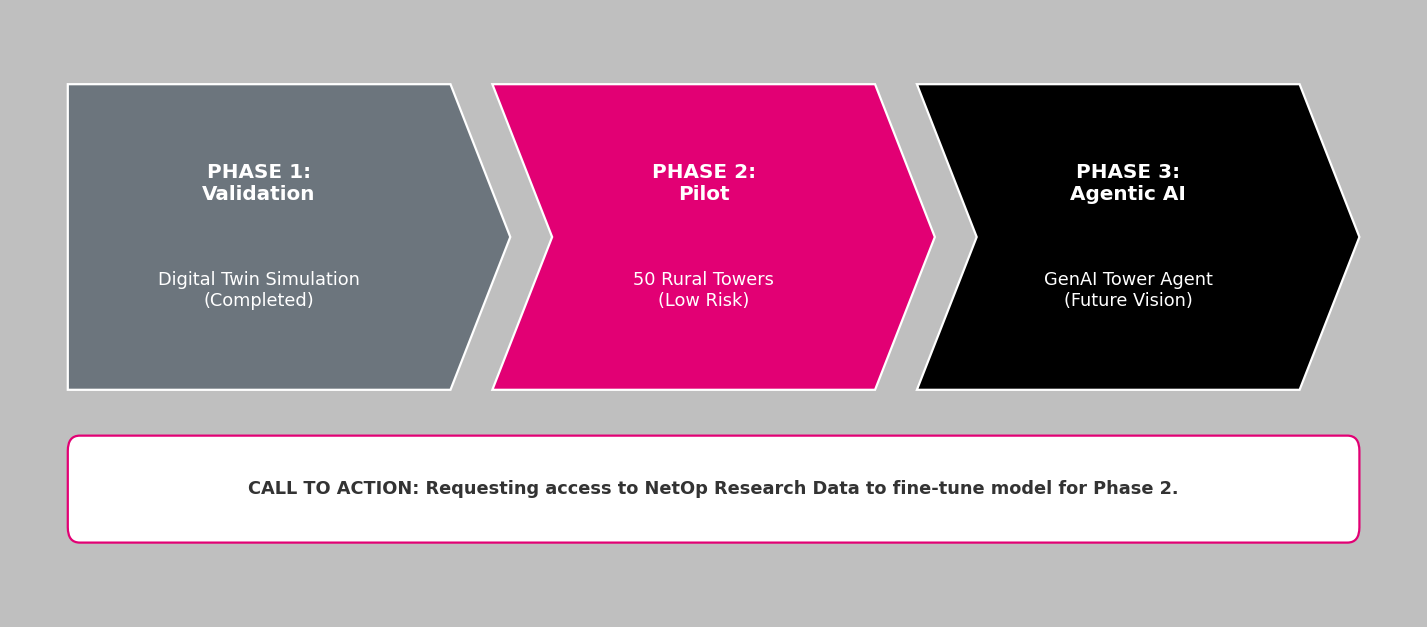

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. SETUP
fig, ax = plt.subplots(figsize=(18, 8)) # Slightly wider to accommodate single-line text
# Y-limits adjusted to focus on the content
plt.ylim(-1.5, 2.5) 
ax.axis('off')

# 2. PARAMETERS (Define these first to calculate totals)
width = 3.2 # Made chevrons slightly wider to fit larger text comfortably
height = 2
head_width = 0.5
gap = 0.1

# Calculate the precise total width of the 3-chevron group
# Logic: Start of 3rd chevron + Width + Tip
last_start_x = 2 * (width + head_width/2 + gap)
total_chevron_width = last_start_x + width + head_width

# Set X-limits to center the content
plt.xlim(-0.5, total_chevron_width + 0.5)

# 3. DATA FOR PHASES
phases = [
    {
        "title": "PHASE 1:\nValidation",
        "desc": "Digital Twin Simulation\n(Completed)",
        "color": "#6c757d",  
        "text_color": "white"
    },
    {
        "title": "PHASE 2:\nPilot",
        "desc": "50 Rural Towers\n(Low Risk)",
        "color": "#E20074",  
        "text_color": "white"
    },
    {
        "title": "PHASE 3:\nAgentic AI",
        "desc": "GenAI Tower Agent\n(Future Vision)",
        "color": "black",
        "text_color": "white"
    }
]

# 4. DRAW CHEVRONS
def get_chevron_points(start_x, width, height, head_width):
    return [
        (start_x, 0),                       
        (start_x + width, 0),               
        (start_x + width + head_width, height/2), 
        (start_x + width, height),          
        (start_x, height),                  
        (start_x + head_width, height/2)    
    ]

for i, phase in enumerate(phases):
    current_start = i * (width + head_width/2 + gap)
    
    # Points
    pts = get_chevron_points(current_start, width, height, head_width)
    
    # Flatten first tail
    if i == 0:
        pts = [
            (current_start, 0),
            (current_start + width, 0),
            (current_start + width + head_width, height/2),
            (current_start + width, height),
            (current_start, height)
        ]

    # Draw
    poly = patches.Polygon(pts, closed=True, color=phase['color'], ec='white', lw=2)
    ax.add_patch(poly)
    
    # Text positioning
    text_x = current_start + width/2 + head_width/3
    if i == 0: text_x = current_start + width/2 
    
    # Title
    plt.text(text_x, 1.35, phase['title'], ha='center', va='center', 
             fontsize=18, fontweight='bold', color=phase['text_color'])
    
    # Description (Increased Size to 16)
    plt.text(text_x, 0.65, phase['desc'], ha='center', va='center', 
             fontsize=16, color=phase['text_color'])

# 5. DRAW THE CALL TO ACTION BOX (Adjusted)
box_pad = 0.1
target_width = total_chevron_width
target_x = 0  # Starts at 0 to match chevrons

inner_width = target_width - (2 * box_pad)
inner_x = target_x + box_pad

# Height adjustment
target_height = 0.7
inner_height = target_height - (2 * box_pad)

# Y position (Centered below)
target_y_top = -0.3 
target_y_bottom = target_y_top - target_height
inner_y = target_y_bottom + box_pad

rect = patches.FancyBboxPatch(
    (inner_x, inner_y), 
    inner_width, 
    inner_height,
    boxstyle=f"round,pad={box_pad}", 
    linewidth=2, 
    edgecolor='#E20074', 
    facecolor='white'
)
ax.add_patch(rect)

# 6. ADD TEXT CENTERED IN BOX (Single Line)
center_x = total_chevron_width / 2
center_y = target_y_bottom + (target_height / 2)

# Removed \n for single line
cta_text = "CALL TO ACTION: Requesting access to NetOp Research Data to fine-tune model for Phase 2."

plt.text(
    center_x, center_y, 
    cta_text, 
    ha='center', va='center', 
    fontsize=16, fontweight='bold', 
    color='#333333'
)

# 7. SAVE
plt.tight_layout()
plt.savefig('roadmap_chevron_final_v2.png', dpi=300, bbox_inches='tight')
plt.show()